# Nhiệm vụ 1: Học không giám sát & Giảm chiều dữ liệu (PCA)

Dữ liệu: `cgv_eda_cleaned.csv` (kết quả của bước EDA).

Các bước:
1. Chuẩn bị đặc trưng (số + đặc trưng suy ra + mã hóa biến phân loại)
2. **Chuẩn hóa đặc trưng** bằng `StandardScaler` (so sánh thêm với `MinMaxScaler`)
3. **Chọn số thành phần** theo Cumulative Explained Variance Ratio (giữ 85% – 95% phương sai)
4. **Đầu ra trực quan**: biểu đồ phương sai dạng khuỷu tay (Elbow-style) và biểu đồ phân tán 2D/3D

## 1. Đọc dữ liệu

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA

plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42

df = pd.read_csv("cgv_eda_cleaned.csv", encoding="utf-8-sig")
print("Số dòng:", len(df))
print("Số cột:", len(df.columns))
print("Tổng giá trị thiếu:", int(df.isna().sum().sum()))
df.head()

Số dòng: 1172
Số cột: 18
Tổng giá trị thiếu: 0


,MovieName,Cinema,ShowDate,Format,ShowTime,GeneratedText,TicketPrice,AvailableSeats,TotalSeats,MovieURL,Rating,Director,Actors,Genre,ReleaseDate,Duration,Language,DurationMinutes
0,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU ...,CGV Crescent Mall,2026-10-01,2D Phụ Đề Việt | Rạp Lamour,10:30,Tôi đã có cơ hội xem suất chiếu AVENGERS: HỒI ...,65000,72,100,https://www.cgv.vn/default/avengers-endgame-en...,T13,"Anthony Russo, Joe Russo","Robert Downey Jr., Chris Evans, Mark Ruffalo, ...","Hành Động, Khoa Học Viễn Tưởng, Phiêu Lưu",2026-09-25,183 phút,Tiếng Anh với phụ đề tiếng Việt,183.0
1,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU ...,CGV Crescent Mall,2026-10-01,2D Phụ Đề Việt | Rạp Lamour,16:00,"Hôm nay, tôi có cơ hội tham gia vào một trải n...",70000,65,100,https://www.cgv.vn/default/avengers-endgame-en...,T13,"Anthony Russo, Joe Russo","Robert Downey Jr., Chris Evans, Mark Ruffalo, ...","Hành Động, Khoa Học Viễn Tưởng, Phiêu Lưu",2026-09-25,183 phút,Tiếng Anh với phụ đề tiếng Việt,183.0
2,AVENGERS: HỒI KẾT - PHIÊN BẢN ĐẶC BIỆT (CHIẾU ...,CGV Crescent Mall,2026-10-01,2D Phụ Đề Việt | Rạp Lamour,21:30,Tôi đã có cơ hội xem suất chiếu AVENGERS: HỒI ...,75000,53,100,https://www.cgv.vn/default/avengers-endgame-en...,T13,"Anthony Russo, Joe Russo","Robert Downey Jr., Chris Evans, Mark Ruffalo, ...","Hành Động, Khoa Học Viễn Tưởng, Phiêu Lưu",2026-09-25,183 phút,Tiếng Anh với phụ đề tiếng Việt,183.0
3,CHIIKAWA: BÍ MẬT ĐẢO NGƯỜI CÁ,CGV Crescent Mall,2026-10-01,2D Phụ Đề Anh & Việt,18:00,"Hôm nay, tôi đã có cơ hội đến rạp chiếu CGV Cr...",80000,79,100,https://www.cgv.vn/default/chiikawa-the-movie....,p,Kei Oikawa,"Haruka Aoki, Makoto Tanaka, Ari Ozawa, Yuka Ig...",Hoạt Hình,2026-08-28,99 phút,Tiếng Nhật với phụ đề Việt & Anh; Lồng tiếng Việt,99.0
4,HÒN ĐẢO QUÊN LÃNG,CGV Crescent Mall,2026-10-01,2D Lồng Tiếng Việt,19:40,"Tôi vừa có cơ hội xem suất chiếu ""HÒN ĐẢO QUÊN...",75000,67,100,https://www.cgv.vn/default/forgotten-island.html,K,Joel Crawford; Januel Mercado,"H.E.R., Liza Soberano, Dave Franco, Jenny Slat...","Hoạt Hình, Phiêu Lưu",2026-09-25,109 phút,Phụ đề Tiếng Việt & Lồng Tiếng Việt,109.0


## 2. Chuẩn bị ma trận đặc trưng

PCA chỉ làm việc với dữ liệu số, nên:
- **Đặc trưng số gốc:** `TicketPrice`, `AvailableSeats`, `TotalSeats`, `DurationMinutes`.
- **Đặc trưng suy ra:** `OccupancyRate` (tỉ lệ lấp đầy), `ShowHour` (giờ chiếu), `DaysSinceRelease` (số ngày từ lúc phát hành đến suất chiếu), `IsWeekend`, `IsPremiumRoom` (phòng đặc biệt như IMAX, 4DX, GOLD CLASS...).
- **Biến phân loại → số:** one-hot cho `Cinema`, `Rating`, loại định dạng chiếu (`FormatTech`); multi-hot cho `Genre`.
- Bỏ các cột văn bản/định danh không phù hợp PCA: `MovieName`, `GeneratedText`, `MovieURL`, `Director`, `Actors`, `Language`, `Duration` (đã có `DurationMinutes`).

In [2]:
feat = pd.DataFrame(index=df.index)

# --- Đặc trưng số gốc ---
num_cols = ["TicketPrice", "AvailableSeats", "TotalSeats", "DurationMinutes"]
for col in num_cols:
    feat[col] = pd.to_numeric(df[col], errors="coerce")

# --- Đặc trưng suy ra ---
feat["OccupancyRate"] = (df["TotalSeats"] - df["AvailableSeats"]) / df["TotalSeats"]
feat["ShowHour"] = pd.to_datetime(df["ShowTime"], format="%H:%M", errors="coerce").dt.hour \
                   + pd.to_datetime(df["ShowTime"], format="%H:%M", errors="coerce").dt.minute / 60

show_date = pd.to_datetime(df["ShowDate"], format="%Y-%m-%d", errors="coerce")
release_date = pd.to_datetime(df["ReleaseDate"], format="%Y-%m-%d", errors="coerce")
feat["DaysSinceRelease"] = (show_date - release_date).dt.days
feat["IsWeekend"] = (show_date.dt.dayofweek >= 5).astype(int)

# Format: tách loại công nghệ (2D, IMAX2D, 4DX2D...) và cờ phòng đặc biệt (có "| Rạp ...")
fmt = df["Format"].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
df["FormatTech"] = fmt.str.split(r" Phụ| Lồng", n=1, regex=True).str[0].str.strip()
feat["IsPremiumRoom"] = fmt.str.contains(r"\|", regex=True).astype(int)

# --- Biến phân loại -> số ---
cat_dummies = pd.get_dummies(df[["Cinema", "Rating", "FormatTech"]], dtype=int)
genre_dummies = df["Genre"].str.get_dummies(sep=", ").add_prefix("Genre_")

X = pd.concat([feat, cat_dummies, genre_dummies], axis=1)

print("Số đặc trưng:", X.shape[1])
print("Giá trị thiếu trong X:", int(X.isna().sum().sum()))
X.head()

Số đặc trưng: 33
Giá trị thiếu trong X: 0


,TicketPrice,AvailableSeats,TotalSeats,DurationMinutes,OccupancyRate,ShowHour,DaysSinceRelease,IsWeekend,IsPremiumRoom,Cinema_CGV Crescent Mall,...,Genre_Gia đình,Genre_Hoạt Hình,Genre_Hài,Genre_Hành Động,Genre_Hồi hộp,Genre_Khoa Học Viễn Tưởng,Genre_Kinh Dị,Genre_Phiêu Lưu,Genre_Thần thoại,Genre_Tâm Lý
0,65000,72,100,183.0,0.28,10.500000,6,0,1,1,...,0,0,0,1,0,1,0,1,0,0
1,70000,65,100,183.0,0.35,16.000000,6,0,1,1,...,0,0,0,1,0,1,0,1,0,0
2,75000,53,100,183.0,0.47,21.500000,6,0,1,1,...,0,0,0,1,0,1,0,1,0,0
3,80000,79,100,99.0,0.21,18.000000,34,0,0,1,...,0,1,0,0,0,0,0,0,0,0
4,75000,67,100,109.0,0.33,19.666667,6,0,0,1,...,0,1,0,0,0,0,0,1,0,0


In [3]:
# Kiểm tra nhanh: đặc trưng không đổi (phương sai = 0) không mang thông tin cho PCA
zero_var = X.columns[X.var() == 0].tolist()
print("Đặc trưng phương sai = 0:", zero_var)
X = X.drop(columns=zero_var)
print("Số đặc trưng dùng cho PCA:", X.shape[1])

Đặc trưng phương sai = 0: []
Số đặc trưng dùng cho PCA: 33


## 3. Chuẩn hóa đặc trưng (Feature Scaling)

PCA dựa trên phương sai, nên đặc trưng có thang đo lớn (ví dụ `TicketPrice` ~ 100.000) sẽ lấn át các đặc trưng nhỏ (ví dụ cờ 0/1). Vì vậy cần chuẩn hóa trước khi huấn luyện PCA.

Dùng **`StandardScaler`** làm phương án chính (mean = 0, std = 1).

In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Kích thước:", X_scaled.shape)
print("Trung bình sau chuẩn hóa (tối đa |mean|):", np.abs(X_scaled.mean(axis=0)).max().round(6))
print("Độ lệch chuẩn sau chuẩn hóa (min / max):",
      X_scaled.std(axis=0).min().round(3), "/", X_scaled.std(axis=0).max().round(3))

Kích thước: (1172, 33)
Trung bình sau chuẩn hóa (tối đa |mean|): 0.0
Độ lệch chuẩn sau chuẩn hóa (min / max): 1.0 / 1.0


**Nhận xét:** Sau chuẩn hóa, trung bình của mọi đặc trưng bằng 0 và độ lệch chuẩn bằng 1, nên `TicketPrice` (khoảng 60.000–120.000) không còn lấn át các cờ 0/1. Dữ liệu có 33 đặc trưng, không có đặc trưng nào phương sai bằng 0 và không có giá trị thiếu.

## 4. Lựa chọn thành phần (Component Selection)

Huấn luyện PCA với toàn bộ thành phần, sau đó tính **Cumulative Explained Variance Ratio**.

In [5]:
pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_scaled)

explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)

var_table = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(explained))],
    "Explained_Variance_Ratio": explained,
    "Cumulative_Ratio": cumulative,
})
var_table.head(15).round(4)

,Component,Explained_Variance_Ratio,Cumulative_Ratio
0,PC1,0.1769,0.1769
1,PC2,0.1518,0.3287
2,PC3,0.0879,0.4166
3,PC4,0.0660,0.4826
4,PC5,0.0603,0.5429
5,PC6,0.0501,0.5930
6,PC7,0.0462,0.6392
7,PC8,0.0448,0.6840
8,PC9,0.0404,0.7245
9,PC10,0.0362,0.7607


In [6]:
# Số thành phần tối thiểu để giữ lại 85% - 95% phương sai
thresholds = [0.85, 0.90, 0.95]
n_needed = {t: int(np.argmax(cumulative >= t) + 1) for t in thresholds}

for t, n in n_needed.items():
    print(f"Giữ >= {t:.0%} phương sai: cần {n} thành phần (thực tế {cumulative[n-1]:.2%})")

# Chọn ngưỡng 90% (nằm giữa khoảng 85% - 95%)
TARGET = 0.90
n_components = n_needed[TARGET]
print(f"\n=> Chọn n_components = {n_components} (giữ {cumulative[n_components-1]:.2%} phương sai, "
      f"giảm từ {X_scaled.shape[1]} xuống {n_components} chiều)")

Giữ >= 85% phương sai: cần 13 thành phần (thực tế 85.23%)
Giữ >= 90% phương sai: cần 15 thành phần (thực tế 90.36%)
Giữ >= 95% phương sai: cần 18 thành phần (thực tế 96.65%)

=> Chọn n_components = 15 (giữ 90.36% phương sai, giảm từ 33 xuống 15 chiều)


**Nhận xét:** Chọn ngưỡng 90% cho kết quả **15 thành phần**, giữ 90,36% phương sai, giảm từ 33 xuống 15 chiều (khoảng 55% số chiều). Ngưỡng 90% nằm giữa khoảng 85–95% theo yêu cầu, cân bằng giữa việc giữ thông tin và giảm chiều. Số chiều chỉ giảm vừa phải vì dữ liệu có nhiều đặc trưng one-hot gần như độc lập (`Cinema`, `Rating`, `FormatTech`, `Genre`), mỗi đặc trưng chỉ mang một phần nhỏ phương sai.

In [7]:
# Huấn luyện lại PCA với số thành phần đã chọn
pca = PCA(n_components=n_components, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(X_pca, columns=[f"PC{i+1}" for i in range(n_components)])
print("Kích thước sau PCA:", X_pca.shape)
print("Tổng phương sai giữ lại:", pca.explained_variance_ratio_.sum().round(4))
pca_df.head()

Kích thước sau PCA: (1172, 15)
Tổng phương sai giữ lại: 0.9036


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15
0,-3.353472,-0.345643,0.507409,-3.103541,0.032181,-0.134756,-2.831837,-0.295313,1.788290,-0.579728,-0.350939,0.612081,-0.867480,0.286481,-0.058166
1,-3.441774,0.100119,0.646921,-3.250165,-0.010412,-0.265523,-2.119653,-0.320902,1.918974,0.247194,-0.226617,0.388293,-0.094746,0.199133,-0.191261
2,-3.507427,0.782761,0.797974,-3.520706,-0.088427,-0.490887,-1.305104,-0.337094,2.034292,1.174404,-0.076993,0.131599,0.696548,0.260005,-0.499438
3,2.103855,-4.174010,-1.895812,-1.205953,2.772197,1.172694,0.514757,0.246437,2.857944,1.465222,5.493055,-4.254387,-2.084332,1.510156,0.284760
4,0.319415,-2.665119,-1.839564,-0.934383,-0.862276,-0.819968,-0.188566,-0.164316,2.201916,0.576777,-0.444142,0.224024,1.905852,0.536961,-0.374576


## 5. Đầu ra trực quan

### 5.1. Biểu đồ phương sai dạng khuỷu tay (Elbow-style)

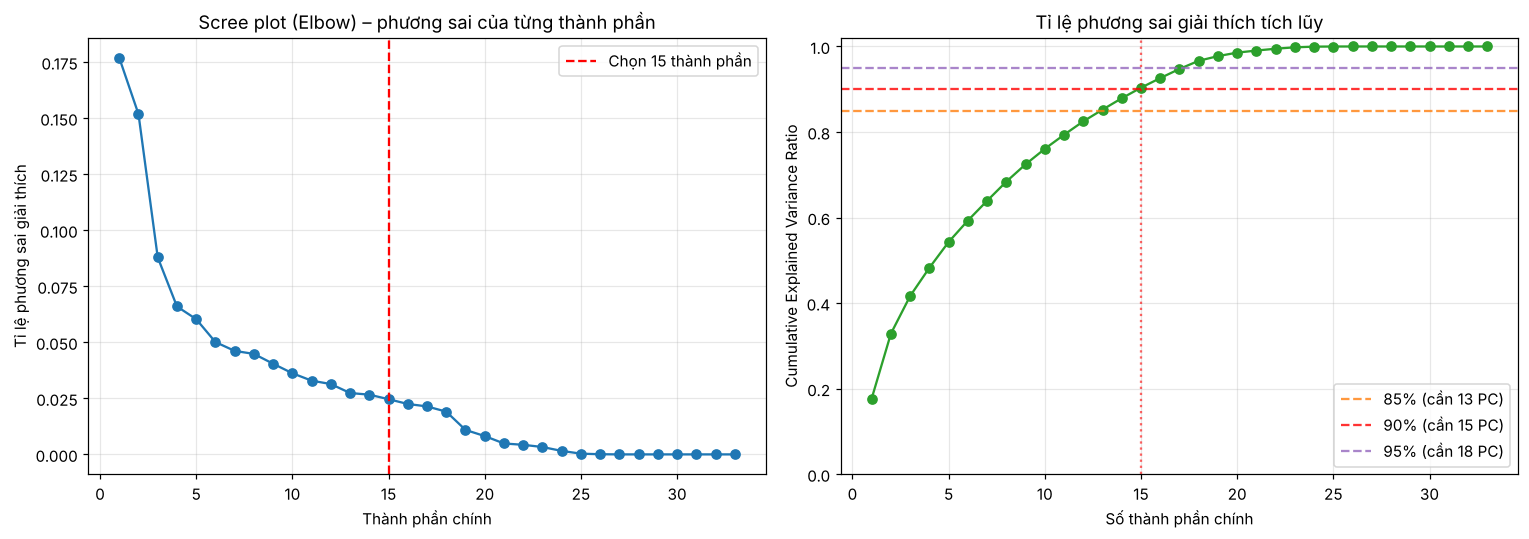

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) Scree / Elbow: phương sai giải thích của từng thành phần
x = np.arange(1, len(explained) + 1)
axes[0].plot(x, explained, marker="o", color="#1f77b4")
axes[0].axvline(n_components, color="red", linestyle="--", label=f"Chọn {n_components} thành phần")
axes[0].set_title("Scree plot (Elbow) – phương sai của từng thành phần")
axes[0].set_xlabel("Thành phần chính")
axes[0].set_ylabel("Tỉ lệ phương sai giải thích")
axes[0].legend()
axes[0].grid(alpha=0.3)

# (b) Phương sai tích lũy với các ngưỡng 85% / 90% / 95%
axes[1].plot(x, cumulative, marker="o", color="#2ca02c")
for t, col in zip(thresholds, ["#ff7f0e", "red", "#9467bd"]):
    axes[1].axhline(t, color=col, linestyle="--", alpha=0.8, label=f"{t:.0%} (cần {n_needed[t]} PC)")
axes[1].axvline(n_components, color="red", linestyle=":", alpha=0.6)
axes[1].set_title("Tỉ lệ phương sai giải thích tích lũy")
axes[1].set_xlabel("Số thành phần chính")
axes[1].set_ylabel("Cumulative Explained Variance Ratio")
axes[1].set_ylim(0, 1.02)
axes[1].legend(loc="lower right")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Nhận xét:**
- **Scree plot (trái):** phương sai giảm mạnh từ PC1 (17,7%) và PC2 (15,2%) xuống PC3 (8,8%), sau đó giảm dần đều. Khuỷu tay xuất hiện ở khoảng PC3, nhưng nếu chỉ lấy 3 thành phần thì mất hơn nửa thông tin.
- **Phương sai tích lũy (phải):** đường cong tăng chậm vì 33 đặc trưng gồm nhiều cờ one-hot độc lập với nhau. Cần **13 / 15 / 18** thành phần để đạt **85% / 90% / 95%** phương sai (thực tế 85,23% / 90,36% / 96,65%).
- Đường 95% nhảy từ 94,x% ở 17 thành phần lên 96,65% ở 18 thành phần, vì vậy thực tế giữ lại 96,65% chứ không đúng 95%.

### 5.2. Biểu đồ phân tán 2D / 3D trong không gian thành phần chính

Màu điểm theo nhãn kiểm duyệt độ tuổi (`Rating`) để quan sát cách dữ liệu phân bố.

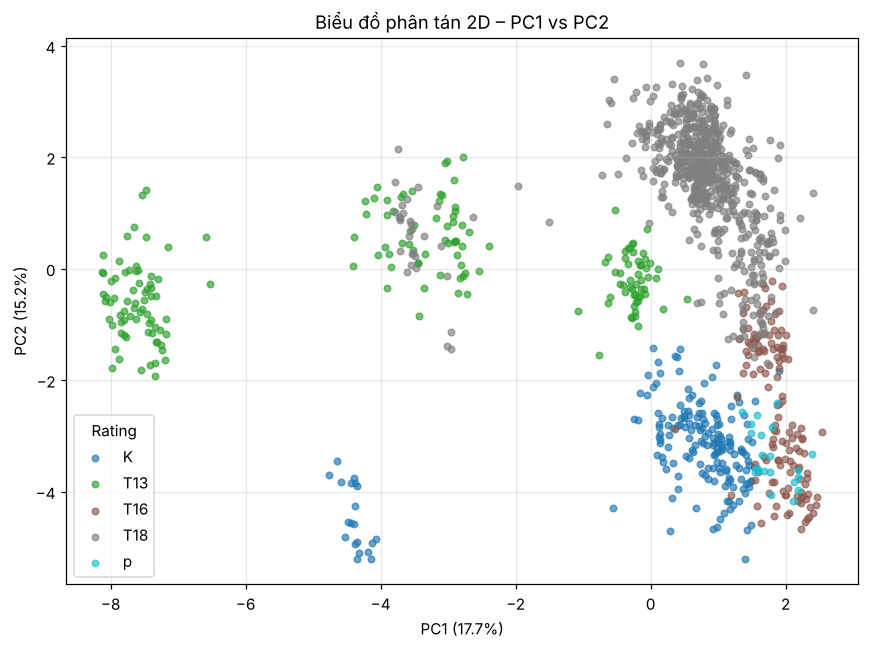

In [9]:
color_col = df["Rating"].astype(str)
categories = sorted(color_col.unique())
palette = dict(zip(categories, plt.cm.tab10(np.linspace(0, 1, len(categories)))))

fig, ax = plt.subplots(figsize=(8, 6))
for cat in categories:
    mask = (color_col == cat).values
    ax.scatter(pca_df.loc[mask, "PC1"], pca_df.loc[mask, "PC2"],
               s=18, alpha=0.65, color=palette[cat], label=cat)
ax.set_xlabel(f"PC1 ({explained[0]:.1%})")
ax.set_ylabel(f"PC2 ({explained[1]:.1%})")
ax.set_title("Biểu đồ phân tán 2D – PC1 vs PC2")
ax.legend(title="Rating")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Nhận xét 2D:** Hai thành phần đầu giữ 32,9% phương sai (17,7% + 15,2%), nhưng các điểm đã tách thành nhiều cụm rõ.
- Nhóm **T13** nằm riêng ở bên trái (PC1 từ −8 đến −2) và một nhóm T13 nhỏ ở gần 0, tương ứng các suất phim khoa học viễn tưởng, phiêu lưu chiếu ở phòng đặc biệt.
- Nhóm **T18** tụ dày ở phía trên bên phải (PC2 dương), là nhóm đông nhất vì 'Trại buồn người' chiếm 41,6% số suất.
- Nhóm **K**, **T16** và **P** nằm ở phía dưới bên phải và chồng lấn một phần với nhau.
- Cụm nhỏ ở dưới bên trái (PC1 ≈ −4,5; PC2 ≈ −4,5) gồm các suất nhãn K ở phòng đặc biệt.
- Các điểm xa cụm chính không phải ngoại lệ lỗi, mà là suất của các phim ít suất hoặc phòng đặc biệt. Nhãn `p` viết thường là một nhóm riêng (21 suất) và nên được chuẩn hóa thành `P` nếu muốn gộp.

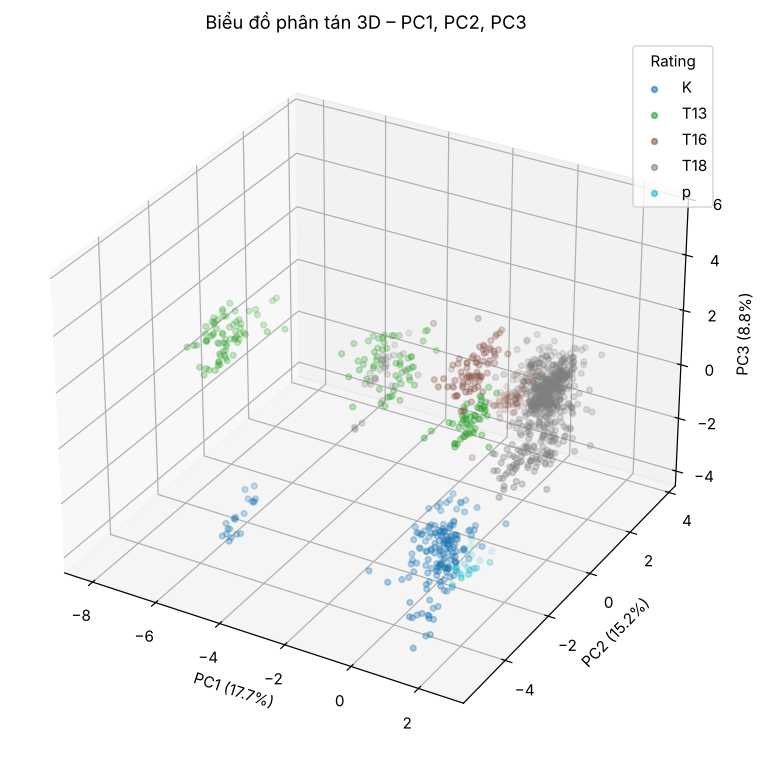

In [10]:
if n_components >= 3:
    fig = plt.figure(figsize=(9, 7))
    ax = fig.add_subplot(111, projection="3d")
    for cat in categories:
        mask = (color_col == cat).values
        ax.scatter(pca_df.loc[mask, "PC1"], pca_df.loc[mask, "PC2"], pca_df.loc[mask, "PC3"],
                   s=14, alpha=0.6, color=palette[cat], label=cat)
    ax.set_xlabel(f"PC1 ({explained[0]:.1%})")
    ax.set_ylabel(f"PC2 ({explained[1]:.1%})")
    ax.set_zlabel(f"PC3 ({explained[2]:.1%})")
    ax.set_title("Biểu đồ phân tán 3D – PC1, PC2, PC3")
    ax.legend(title="Rating")
    plt.tight_layout()
    plt.show()

**Nhận xét 3D:** Thêm PC3 (8,8%) cho tổng ba thành phần đầu là 41,7% phương sai, nên không gian 3 chiều vẫn chỉ giữ chưa đến một nửa thông tin. PC3 chủ yếu tách các nhóm phim gia đình, tâm lý, nhãn T16 khỏi hoạt hình, nhãn K, giúp nhìn rõ hơn nhóm chồng lấn ở góc phải dưới của biểu đồ 2D.

### 5.3. Đặc trưng nào đóng góp nhiều nhất vào các thành phần chính?

In [11]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=X.columns,
    columns=[f"PC{i+1}" for i in range(n_components)],
)

for pc in ["PC1", "PC2", "PC3"]:
    if pc in loadings.columns:
        print(f"Top 5 đặc trưng ảnh hưởng nhất tới {pc}:")
        print(loadings[pc].reindex(loadings[pc].abs().sort_values(ascending=False).index).head(5).round(3))
        print()

Top 5 đặc trưng ảnh hưởng nhất tới PC1:
FormatTech_2D                0.353
Genre_Khoa Học Viễn Tưởng   -0.344
Genre_Phiêu Lưu             -0.333
Rating_T13                  -0.302
IsPremiumRoom               -0.297
Name: PC1, dtype: float64

Top 5 đặc trưng ảnh hưởng nhất tới PC2:
Genre_Hành Động    0.379
Rating_T18         0.355
AvailableSeats    -0.351
OccupancyRate      0.344
Genre_Hồi hộp      0.308
Name: PC2, dtype: float64

Top 5 đặc trưng ảnh hưởng nhất tới PC3:
Rating_T16         0.464
Genre_Gia đình     0.444
Genre_Tâm Lý       0.444
Genre_Hoạt Hình   -0.355
Rating_K          -0.334
Name: PC3, dtype: float64



**Nhận xét:**
- **PC1 (17,7%)** tách phòng 2D thường (+0,35) khỏi nhóm phim khoa học viễn tưởng, phiêu lưu, nhãn T13 và phòng đặc biệt (âm, từ −0,30 đến −0,34), tức là trục "bom tấn chiếu phòng đặc biệt" so với "suất 2D thông thường".
- **PC2 (15,2%)** gắn với phim hành động, hồi hộp, nhãn T18 và tỉ lệ lấp đầy cao (+0,34 đến +0,38), đối lập với số ghế trống (−0,35). Đây là trục "phim hành động nhãn T18, đông khách".
- **PC3 (8,8%)** đối lập phim gia đình, tâm lý, nhãn T16 (+0,44 đến +0,46) với hoạt hình và nhãn K (−0,33 đến −0,36).
- Các thành phần chính chủ yếu mô tả **đặc điểm phim** (thể loại, nhãn tuổi, loại phòng). Giá vé, giờ chiếu hay cuối tuần không nằm trong top 5 của ba thành phần đầu.

## 6. So sánh `StandardScaler` và `MinMaxScaler`

Yêu cầu cho phép dùng một trong hai bộ chuẩn hóa. Bảng dưới so sánh số thành phần cần thiết khi dùng từng loại.

In [12]:
rows = []
for name, sc in [("StandardScaler", StandardScaler()), ("MinMaxScaler", MinMaxScaler())]:
    Xs = sc.fit_transform(X)
    cum = np.cumsum(PCA(random_state=RANDOM_STATE).fit(Xs).explained_variance_ratio_)
    rows.append({"Scaler": name, **{f"Số PC cho {t:.0%}": int(np.argmax(cum >= t) + 1) for t in thresholds}})

pd.DataFrame(rows)

,Scaler,Số PC cho 85%,Số PC cho 90%,Số PC cho 95%
0,StandardScaler,13,15,18
1,MinMaxScaler,10,12,15


**Nhận xét:** Với `MinMaxScaler`, số thành phần cần cho 85% / 90% / 95% phương sai là 10 / 12 / 15, ít hơn `StandardScaler` (13 / 15 / 18). `MinMaxScaler` nén mọi đặc trưng về [0, 1] nên các cờ 0/1 và biến liên tục có phương sai gần nhau, còn `StandardScaler` cho mỗi đặc trưng phương sai bằng 1 và vì thế giữ nhiều chiều độc lập hơn. Mục tiêu là cho mọi đặc trưng đóng góp công bằng nên giữ `StandardScaler` làm phương án chính.

## 7. Kết luận

- Dữ liệu v3 gồm 1.172 suất chiếu, 33 đặc trưng sau mã hóa, không thiếu giá trị. Đã chuẩn hóa bằng `StandardScaler` trước khi chạy PCA.
- Cần **13 / 15 / 18** thành phần để giữ **85% / 90% / 95%** phương sai. Mô hình cuối chọn ngưỡng 90%: **15 thành phần, giữ 90,36% phương sai, giảm từ 33 xuống 15 chiều**.
- Ba thành phần đầu giữ 41,7% phương sai và chủ yếu mô tả đặc điểm phim: PC1 là phòng đặc biệt, phim bom tấn so với suất 2D thường; PC2 là phim hành động nhãn T18 đông khách; PC3 là phim gia đình, tâm lý so với hoạt hình.
- Biểu đồ 2D cho thấy dữ liệu tách thành nhiều cụm rõ theo nhãn tuổi (T13 tách xa, T18 tụ dày, K/T16/P chồng lấn), cho thấy dữ liệu có cấu trúc đủ để phân cụm ở Task 2.
- Với `MinMaxScaler`, chỉ cần 10 / 12 / 15 thành phần; `StandardScaler` được giữ làm phương án chính.
- Lưu ý: ba cột `TicketPrice`, `TotalSeats`, `AvailableSeats` là dữ liệu mô phỏng theo quy luật giả định, nên cấu trúc tìm được phản ánh cơ cấu lịch chiếu và quy luật mô phỏng, không phải hành vi khách thật.
- Dữ liệu sau PCA nằm trong `pca_df` và được lưu vào `cgv_pca_result.csv` để dùng cho Task 2.

In [13]:
# (Tùy chọn) Lưu dữ liệu sau PCA để dùng cho bước tiếp theo
pca_df.to_csv("cgv_pca_result.csv", index=False, encoding="utf-8-sig")
print("Đã lưu cgv_pca_result.csv")

Đã lưu cgv_pca_result.csv
